# Semana 8. Implementación y comparación de algoritmos de clasificación

**Asignatura:** Introducción a Machine Learning  
**Institución:** Universidad de Cundinamarca – CADI  
**Estudiante:** Yerson Ronaldo Rivas Ruiz  
**Tema:** Comparación de cinco algoritmos de clasificación mediante Scikit-learn.

## Objetivo

Implementar y comparar Decision Tree, Random Forest, Support Vector Machine (SVM), K-Nearest Neighbors (K-NN) y Naive Bayes utilizando el conjunto de datos Breast Cancer Wisconsin Diagnostic. El análisis se realizará mediante Accuracy, Precision, Recall, F1-score y matrices de confusión para seleccionar el modelo más adecuado según sus resultados y el contexto del problema.

## Alcance

El ejercicio tiene fines exclusivamente académicos. Los resultados no constituyen una herramienta de diagnóstico médico ni deben utilizarse para tomar decisiones clínicas.

In [2]:

# Importar las bibliotecas necesarias para el análisis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Configurar la visualización de tablas
pd.set_option("display.max_columns", None)

In [3]:

# Cargar el conjunto de datos de Scikit-learn
data = load_breast_cancer(as_frame=True)

# Guardar las variables de entrada
X = data.data.copy()

# Definir la variable objetivo:
# 1 = maligno; 0 = benigno
y = (data.target == 0).astype(int)

# Mostrar las dimensiones del conjunto de datos
print("Número de observaciones:", X.shape[0])
print("Número de variables de entrada:", X.shape[1])

# Mostrar la distribución de la variable objetivo
print("\nDistribución de los diagnósticos:")
print(y.value_counts().rename(index={0: "Benigno", 1: "Maligno"}))

print("\nPorcentaje por clase:")
print((y.value_counts(normalize=True) * 100).round(2))

# Revisar valores faltantes
print("\nValores faltantes:", X.isnull().sum().sum())

# Mostrar las primeras filas
display(X.head())

Número de observaciones: 569
Número de variables de entrada: 30

Distribución de los diagnósticos:
target
Benigno    357
Maligno    212
Name: count, dtype: int64

Porcentaje por clase:
target
0    62.74
1    37.26
Name: proportion, dtype: float64

Valores faltantes: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


El conjunto contiene 569 observaciones y 30 variables de entrada numéricas. La clase benigna corresponde a 357 casos y la maligna a 212. Por tanto, las clases no están distribuidas de manera uniforme, aunque tampoco existe un desequilibrio extremo. No se observan valores faltantes en las variables de entrada.
La clase positiva se definió como maligna para que el Recall permita evaluar qué proporción de los casos malignos reales identifica cada modelo.

In [4]:

# Dividir los datos en entrenamiento (80 %) y prueba (20 %)
# random_state garantiza que la división sea reproducible.
# stratify conserva aproximadamente la proporción de las clases.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

print("\nDistribución de clases en entrenamiento:")
print(y_train.value_counts())

print("\nDistribución de clases en prueba:")
print(y_test.value_counts())


Datos de entrenamiento: (455, 30)
Datos de prueba: (114, 30)

Distribución de clases en entrenamiento:
target
0    285
1    170
Name: count, dtype: int64

Distribución de clases en prueba:
target
0    72
1    42
Name: count, dtype: int64


**Interpretación:** stratify=y mantiene aproximadamente la proporción original de casos benignos y malignos en ambos conjuntos. La división se realiza una sola vez para garantizar una comparación justa entre los cinco modelos.

In [6]:

# Crear una función que calcule las mismas métricas para todos
# los clasificadores y permita comparar sus resultados.

def evaluar_modelo(nombre, modelo, X_eval, y_eval):
    pred = modelo.predict(X_eval)

    resultados = {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision": precision_score(
            y_eval, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_eval, pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_eval, pred, zero_division=0
        )
    }

    print(f"\nMatriz de confusión: {nombre}")
    print(confusion_matrix(y_eval, pred, labels=[0, 1]))

    return resultados


La función evita repetir cálculos y asegura que todos los modelos se evalúen con las mismas métricas. En las matrices de confusión, el orden de las clases será benigno (0) y maligno (1).

In [7]:

# Definir los cinco clasificadores según los parámetros de la guía.

modelos = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=1.0, gamma="scale")
    ),

    "K-NN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Naive Bayes": GaussianNB()
}

# Entrenar cada modelo y guardar los resultados.
resultados = []

for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)

    resultado = evaluar_modelo(
        nombre,
        modelo,
        X_test,
        y_test
    )

    resultados.append(resultado)

print("\nLos cinco modelos fueron entrenados y evaluados.")



Matriz de confusión: Decision Tree
[[70  2]
 [ 8 34]]

Matriz de confusión: Random Forest
[[72  0]
 [ 3 39]]

Matriz de confusión: SVM
[[72  0]
 [ 3 39]]

Matriz de confusión: K-NN
[[71  1]
 [ 4 38]]

Matriz de confusión: Naive Bayes
[[72  0]
 [ 7 35]]

Los cinco modelos fueron entrenados y evaluados.


**¿Por qué se escalan SVM y K-NN?**
Estos algoritmos dependen de las distancias o de la escala de las variables. StandardScaler transforma las variables para que tengan una escala comparable. Al utilizar make_pipeline, el escalador se ajusta con los datos de entrenamiento y después transforma los datos de prueba, evitando filtraciones de información.
Decision Tree, Random Forest y GaussianNB se entrenan sin ese escalamiento, tal como solicita la guía.

In [8]:

# Consolidar las métricas de todos los modelos
tabla_resultados = pd.DataFrame(resultados)

# Ordenar por F1-score para facilitar la comparación
tabla_resultados = tabla_resultados.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

# Mostrar las métricas con cuatro decimales
display(
    tabla_resultados.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}"
    })
)


,Modelo,Accuracy,Precision,Recall,F1-score
0,Random Forest,0.9737,1.0000,0.9286,0.9630
1,SVM,0.9737,1.0000,0.9286,0.9630
2,K-NN,0.9561,0.9744,0.9048,0.9383
3,Naive Bayes,0.9386,1.0000,0.8333,0.9091
4,Decision Tree,0.9123,0.9444,0.8095,0.8718


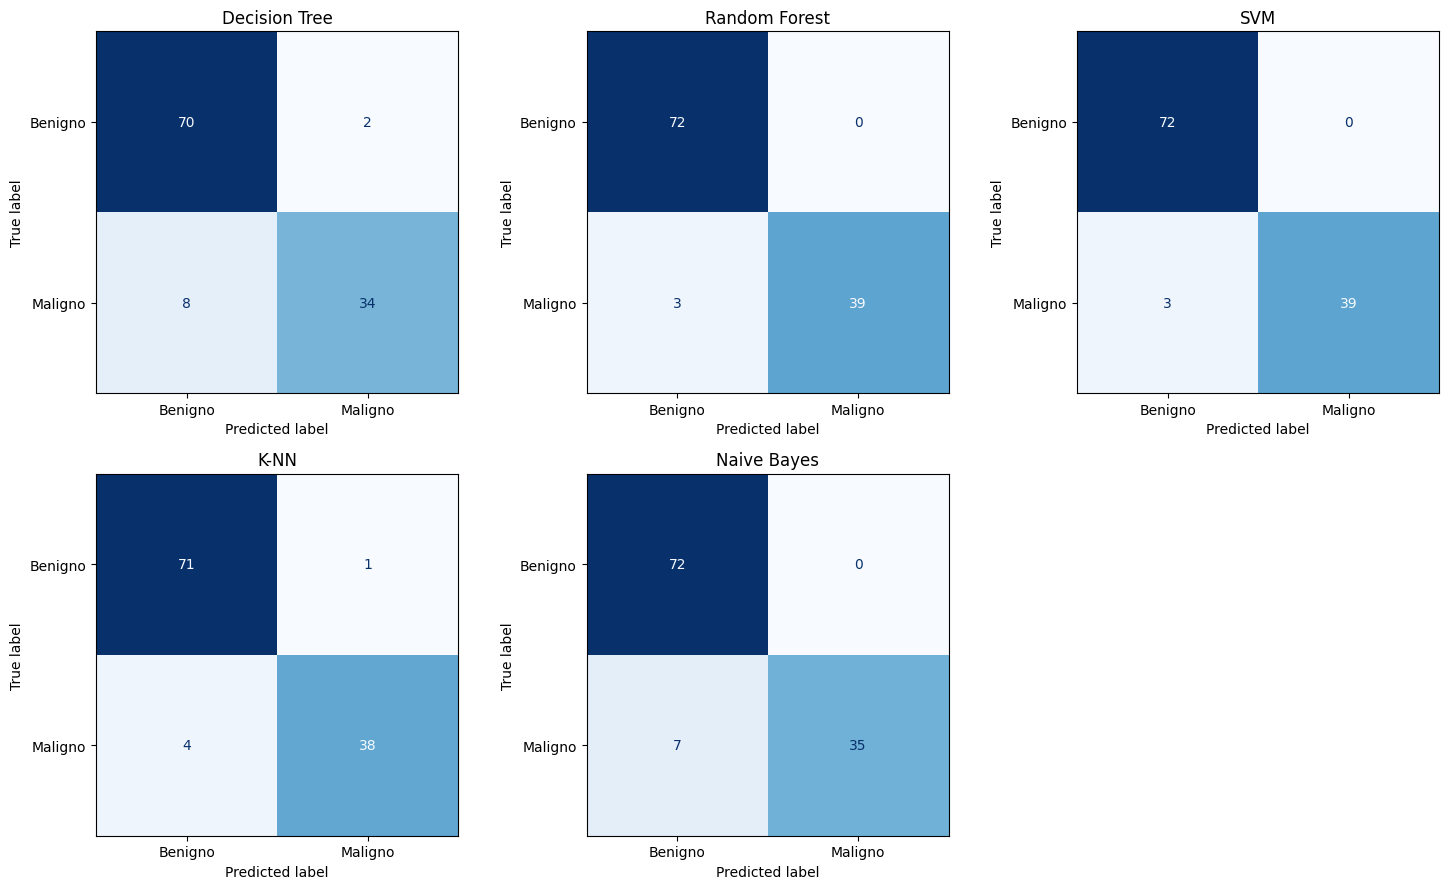

In [9]:

# Representar gráficamente la matriz de confusión
# de cada clasificador para observar sus errores.

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (nombre, modelo) in enumerate(modelos.items()):
    pred = modelo.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        pred,
        labels=[0, 1],
        display_labels=["Benigno", "Maligno"],
        cmap="Blues",
        colorbar=False,
        ax=axes[i]
    )

    axes[i].set_title(nombre)

# Eliminar el sexto espacio, que no tiene modelo
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()


En cada matriz, la fila representa el diagnóstico real y la columna el diagnóstico predicho. El valor más importante en este caso son los falsos negativos: muestras malignas clasificadas erróneamente como benignas.

In [10]:

# Obtener los falsos negativos de cada modelo.
# La matriz usa el orden [benigno, maligno]:
# los falsos negativos están en la posición [1, 0].

comparacion_errores = []

for nombre, modelo in modelos.items():
    pred = modelo.predict(X_test)

    matriz = confusion_matrix(
        y_test,
        pred,
        labels=[0, 1]
    )

    comparacion_errores.append({
        "Modelo": nombre,
        "Falsos positivos": matriz[0, 1],
        "Falsos negativos": matriz[1, 0],
        "Verdaderos positivos": matriz[1, 1],
        "Verdaderos negativos": matriz[0, 0]
    })

tabla_errores = pd.DataFrame(comparacion_errores)

display(tabla_errores.sort_values("Falsos negativos"))


,Modelo,Falsos positivos,Falsos negativos,Verdaderos positivos,Verdaderos negativos
1,Random Forest,0,3,39,72
2,SVM,0,3,39,72
3,K-NN,1,4,38,71
4,Naive Bayes,0,7,35,72
0,Decision Tree,2,8,34,70


In [15]:
# Mostrar los resultados finales en porcentaje
tabla_porcentajes = tabla_resultados.copy()

columnas_metricas = [
    "Accuracy", "Precision", "Recall", "F1-score"
]

tabla_porcentajes[columnas_metricas] = (
    tabla_porcentajes[columnas_metricas] * 100
).round(2)

display(tabla_porcentajes)

,Modelo,Accuracy,Precision,Recall,F1-score
0,Decision Tree,91.23,94.44,80.95,87.18
1,Random Forest,97.37,100.00,92.86,96.30
2,SVM,97.37,100.00,92.86,96.30
3,K-NN,95.61,97.44,90.48,93.83
4,Naive Bayes,93.86,100.00,83.33,90.91


In [13]:
# Validación cruzada de Random Forest con cinco particiones

from sklearn.model_selection import StratifiedKFold, cross_validate

validacion = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

metricas = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1-score": "f1"
}

resultados_cv = cross_validate(
    modelos["Random Forest"],
    X_train,
    y_train,
    cv=validacion,
    scoring=metricas
)

# Mostrar el promedio y la desviación estándar
for metrica in metricas:
    valores = resultados_cv[f"test_{metrica}"]
    print(
        f"{metrica}: {valores.mean():.4f} "
        f"+/- {valores.std():.4f}"
    )

Accuracy: 0.9648 +/- 0.0146
Precision: 0.9641 +/- 0.0107
Recall: 0.9412 +/- 0.0416
F1-score: 0.9519 +/- 0.0207


### Interpretación de la validación cruzada

La validación cruzada de cinco particiones permite evaluar la estabilidad del modelo Random Forest utilizando diferentes divisiones de los datos de entrenamiento. En cada partición, el modelo se entrena con una parte de los datos y se evalúa con la parte restante.

El promedio de las métricas permite observar el desempeño general del modelo, mientras que la desviación estándar muestra cuánto varían los resultados entre las particiones. Una desviación estándar baja indica mayor estabilidad en las particiones evaluadas.

Estos resultados complementan la evaluación realizada con el conjunto de prueba, pero no la reemplazan. La selección final debe considerar tanto el desempeño obtenido como el tipo de errores que se busca reducir.

En estos resultados, Random Forest y SVM empatan en las cuatro métricas. Sin embargo, sus resultados deben interpretarse junto con las matrices de confusión.

Random Forest y SVM
Alcanzan un Recall de 92,86 % y dejan tres falsos negativos cada uno. Ambos ofrecen el mejor equilibrio observado entre las métricas.

Decision Tree
Es más sencillo de interpretar, pero deja ocho falsos negativos, más que los otros clasificadores de mejor desempeño.

K-NN y Naive Bayes
K-NN deja cuatro falsos negativos y Naive Bayes deja siete. Aunque Naive Bayes obtiene una precisión del 100 %, su Recall es inferior al de Random Forest y SVM.

**¿Qué ventaja tiene limitar la profundidad del árbol?**

Limitar la profundidad reduce la complejidad del modelo, facilita su interpretación y ayuda a evitar el sobreajuste. Como contrapartida, un árbol demasiado limitado puede no capturar todos los patrones de los datos.

**¿Qué cambia al pasar de un árbol individual a Random Forest?**

Random Forest combina las predicciones de varios árboles entrenados con muestras y características aleatorizadas. Esto suele reducir la variabilidad de un árbol individual y mejorar la capacidad de generalización.

**¿Por qué SVM utiliza StandardScaler?**

Porque las variables tienen magnitudes diferentes y la escala puede afectar la separación que encuentra el algoritmo. La estandarización ayuda a que las variables sean comparables.

**¿Qué representa k=5 en K-NN?**

Significa que el algoritmo considera los cinco vecinos más cercanos a una observación para determinar su clase mediante votación.

**¿Qué supuesto utiliza Naive Bayes?**

Supone que las variables son condicionalmente independientes entre sí dada la clase. GaussianNB, además, modela cada variable numérica mediante una distribución normal dentro de cada clase.

**¿Qué modelo obtuvo la mayor Accuracy?**

Random Forest y SVM, ambos con 97,37 % en los resultados de referencia.

**¿Qué modelo obtuvo el mayor Recall para la clase maligna?**

Random Forest y SVM, con un Recall de 92,86 %.

¿Qué modelos produjeron menos falsos negativos?

Random Forest y SVM, con tres falsos negativos cada uno.

**¿Coincide el modelo con mayor Accuracy con el que seleccionarías?**

Sí, en este caso ambos modelos también presentan el mayor Recall y F1-score. La elección final entre ellos requiere considerar otros aspectos, como el costo computacional y la facilidad de interpretación.

**Si el costo de no detectar un caso maligno fuera especialmente alto, ¿qué métrica priorizarías?**

Priorizaría el Recall de la clase maligna, porque mide la proporción de casos malignos reales que el modelo identifica. Un Recall alto reduce los falsos negativos, aunque también es necesario revisar la precisión y los demás errores.

**¿Cuál es más sencillo de explicar a una persona no técnica?**

Decision Tree, porque sus decisiones pueden representarse mediante reglas y ramas comprensibles. En este ejercicio, esa facilidad de interpretación debe compararse con su menor Recall.

**¿Qué diferencias observaste entre los algoritmos que requieren escalamiento y los que no?**

SVM y K-NN dependen de distancias o de la geometría de los datos, por lo que el escalamiento es importante. Los árboles y los bosques de árboles se basan en reglas de división y no suelen necesitarlo. Naive Bayes puede utilizarse sin escalamiento en esta práctica, aunque su desempeño depende de los supuestos estadísticos del modelo.

### Selección del modelo

Se selecciona Random Forest como modelo final para esta práctica, debido a su alto desempeño en las métricas evaluadas y a la posibilidad de analizar la importancia de las variables.

El modelo obtuvo una Accuracy del 97,37 %, una Precision del 100 %, un Recall del 92,86 % y un F1-score del 96,30 %. En el conjunto de prueba identificó correctamente 39 de los 42 casos malignos y registró tres falsos negativos.

SVM obtuvo los mismos resultados en las métricas evaluadas. Por tanto, no se puede afirmar que Random Forest sea predictivamente superior en esta prueba. La selección se basa también en la posibilidad de complementar el análisis mediante la importancia de las variables.

Esta elección tiene fines exclusivamente académicos. Los resultados no validan el uso del modelo para realizar diagnósticos médicos.

### Conclusiones

La implementación permitió comparar cinco algoritmos de clasificación utilizando el conjunto de datos Breast Cancer Wisconsin Diagnostic y las mismas particiones de entrenamiento y prueba. Los resultados mostraron diferencias en la capacidad de los modelos para identificar los casos malignos y reducir los errores de clasificación.

Random Forest y SVM obtuvieron los mejores resultados, con una Accuracy del 97,37 % y un Recall del 92,86 %. Ambos identificaron 39 de los 42 casos malignos del conjunto de prueba y clasificaron incorrectamente tres como benignos. Se seleccionó Random Forest por sus resultados y por la posibilidad de analizar la importancia de las variables.

Finalmente, la comparación permitió reconocer que la selección de un algoritmo depende de las métricas obtenidas, el tipo de error que se busca reducir y las características del problema. Los resultados corresponden a una práctica académica y requieren validaciones adicionales antes de considerar cualquier aplicación fuera de este ejercicio.

### Referencias

Scikit-learn. (s. f.). *Breast cancer Wisconsin
(diagnostic) dataset*. https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html

Scikit-learn. (s. f.). *Model evaluation: quantifying the quality of predictions*. https://scikit-learn.org/stable/modules/model_evaluation.html

Universidad de Cundinamarca, CADI. (s. f.). *Introducción a Machine Learning: Semana 8. Implementación y comparación de algoritmos de clasificación*. Guía de trabajo asincrónico.